In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)


Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [2]:
import os
for dp, dn, fn in os.walk(path):
    depth = dp[len(path):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(dp) + "/", f"({len(fn)} files)" if fn else "")


knee-osteoarthritis-dataset-with-severity/ 
  auto_test/ 
    2/ (403 files)
    0/ (604 files)
    3/ (200 files)
    1/ (275 files)
    4/ (44 files)
  val/ 
    2/ (212 files)
    0/ (328 files)
    3/ (106 files)
    1/ (153 files)
    4/ (27 files)
  test/ 
    2/ (447 files)
    0/ (639 files)
    3/ (223 files)
    1/ (296 files)
    4/ (51 files)
  train/ 
    2/ (1516 files)
    0/ (2286 files)
    3/ (757 files)
    1/ (1046 files)
    4/ (173 files)


In [3]:
from torchvision import transforms, datasets
import os, re

# ---- find the folder that contains train / val / test (works whatever the nesting is) ----
def find_base(root):
    for dp, dn, _ in os.walk(root):
        if {"train", "val", "test"} <= set(dn):
            return dp
    raise FileNotFoundError("train/val/test folders not found under " + root)

base = find_base(path)
print("base:", base)          # NOTE: 'auto_test' (if it exists) is NOT used

# ---- choose the task ----------------------------------------------------------------------
# "5class" : KL 0,1,2,3,4 (normal 5-class task)
# "merge01": KL 0+1 merged -> 4 classes  (0-1 | 2 | 3 | 4)
# "binary" : KL 0+1 vs KL>=2 (clinically relevant OA yes/no)
# "drop01" : REMOVE KL 0 and 1 completely -> 3 classes (2 | 3 | 4)  (different, easier task!)
MODE = "drop01"   # delete KL0 + KL1 -> classes: KL2, KL3, KL4

MODES = {
    "5class":  ({0: 0, 1: 1, 2: 2, 3: 3, 4: 4},          ["KL0", "KL1", "KL2", "KL3", "KL4"]),
    "merge01": ({0: 0, 1: 0, 2: 1, 3: 2, 4: 3},          ["KL0-1", "KL2", "KL3", "KL4"]),
    "binary":  ({0: 0, 1: 0, 2: 1, 3: 1, 4: 1},          ["KL0-1", "KL2-4"]),
    "drop01":  ({0: None, 1: None, 2: 0, 3: 1, 4: 2},    ["KL2", "KL3", "KL4"]),
}
LABEL_MAP, CLASS_NAMES = MODES[MODE]
NUM_CLASSES = len(CLASS_NAMES)

def remap(ds):
    """Re-label (or drop) samples of a freshly loaded ImageFolder according to MODE."""
    folder_names = ds.classes                       # e.g. ['0','1','2','3','4']
    samples = []
    for p, c in ds.samples:
        grade = int(re.match(r"\d", folder_names[c]).group())   # KL grade from the folder name
        new = LABEL_MAP[grade]
        if new is not None:
            samples.append((p, new))
    ds.samples = ds.imgs = samples
    ds.targets = [t for _, t in samples]
    ds.classes = CLASS_NAMES
    ds.class_to_idx = {n: i for i, n in enumerate(CLASS_NAMES)}

# Resolution. (If the check below prints 224x224, 224 is the fastest option.)
IMG_SIZE = 224   # fastest. (300 = ~2x slower, only worth it if accuracy is still low)

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)
print("folders found:", train.classes)
for ds in (train, val, test):
    remap(ds)

from PIL import Image
print("original image size:", Image.open(train.samples[0][0]).size)
print("MODE:", MODE, "| classes:", train.classes)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


base: /kaggle/input/knee-osteoarthritis-dataset-with-severity
folders found: ['0', '1', '2', '3', '4']
original image size: (224, 224)
MODE: drop01 | classes: ['KL2', 'KL3', 'KL4']
train: 2446 | val: 345 | test: 721


In [4]:
# Leakage check: are there byte-identical images shared between splits?
import hashlib

def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

H = {n: {md5(p) for p, _ in ds.samples} for n, ds in [("train", train), ("val", val), ("test", test)]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} & {b}: {len(H[a] & H[b])} identical images")
# 0 means no exact duplicates (near-duplicates / same patient can still exist)


train & val: 0 identical images
train & test: 0 identical images
val & test: 0 identical images


In [5]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'KL2': 0, 'KL3': 1, 'KL4': 2}

In [6]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'KL2': 1516, 'KL3': 757, 'KL4': 173}
val {'KL2': 212, 'KL3': 106, 'KL4': 27}
test {'KL2': 447, 'KL3': 223, 'KL4': 51}


In [7]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 2446 (69.65%) | Classes: {'KL2': '1516 (62.0%)', 'KL3': '757 (30.9%)', 'KL4': '173 (7.1%)'}
val   | Total:  345 (9.82%) | Classes: {'KL2': '212 (61.4%)', 'KL3': '106 (30.7%)', 'KL4': '27 (7.8%)'}
test  | Total:  721 (20.53%) | Classes: {'KL2': '447 (62.0%)', 'KL3': '223 (30.9%)', 'KL4': '51 (7.1%)'}


In [8]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.54, 1.08, 4.71]


In [9]:
# (train / val / test pipelines are built once in the next cells)


In [10]:
from torch.utils.data import DataLoader, Dataset
import os

NUM_WORKERS = min(4, os.cpu_count() or 2)
BATCH_SIZE = 32   # if CUDA OOM -> 16


In [11]:
import cv2
import numpy as np
from PIL import Image

# CLAHE contrast enhancement (blur optional, off by default)
class Denoise:
    def __init__(self, blur=False):
        self.blur = blur
    def __call__(self, img):
        g = np.array(img.convert("L"))
        if self.blur:
            g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

norm = [transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]

# one-time (expensive) part: CLAHE + resize  -> done ONCE, not every epoch
pre = transforms.Compose([Denoise(), transforms.Resize((IMG_SIZE, IMG_SIZE))])

# per-epoch (cheap) part
tf = transforms.Compose([transforms.Grayscale(3)] + norm)                       # val / test
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
] + norm)

class CachedDS(Dataset):
    """Keeps the pre-processed (CLAHE + resized, 1-channel) images in RAM."""
    def __init__(self, base_ds, pre, post):
        self.items = []
        for p, y in base_ds.samples:
            with Image.open(p) as im:
                self.items.append((pre(im), y))
        self.post = post
        self.samples, self.targets = base_ds.samples, base_ds.targets
        self.classes, self.class_to_idx = base_ds.classes, base_ds.class_to_idx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        img, y = self.items[i]
        return self.post(img), y

def build(split, post):
    ds = datasets.ImageFolder(f"{base}/{split}")
    remap(ds)
    return CachedDS(ds, pre, post)

print("Caching pre-processed images (one time only)...")
train = build("train", train_tf)
val   = build("val",   tf)
test  = build("test",  tf)

train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


Caching pre-processed images (one time only)...
batch shape: torch.Size([32, 3, 224, 224])
train: 2446 | val: 345 | test: 721


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

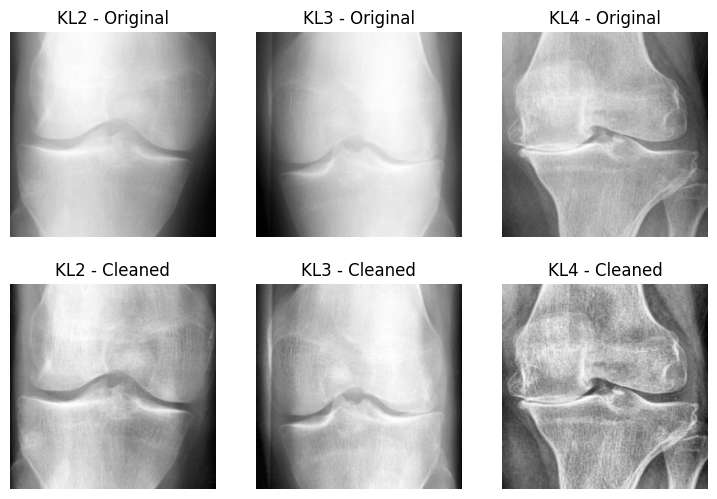

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 6))
for k in range(NUM_CLASSES):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"{CLASS_NAMES[k]} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"{CLASS_NAMES[k]} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

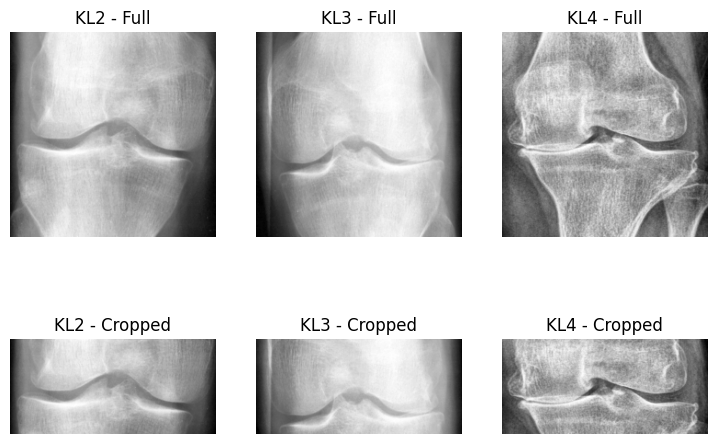

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 6))
for k in range(NUM_CLASSES):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"{CLASS_NAMES[k]} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"{CLASS_NAMES[k]} - Cropped"); axes[1][k].axis("off")
plt.show()


# Agnostic Code

In [14]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (EfficientNet-B5)

## Training

In [15]:
def train_step(model,
               data_loader,
               loss_fn,
               optm,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item() * input.size(0)
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optm.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optm.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [16]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [17]:
from sklearn.metrics import f1_score

def val_macro_f1():
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in val_loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    return f1_score(labels, preds, average="macro")

In [18]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [19]:
from sklearn.metrics import f1_score

# Mixed precision (AMP) -> less GPU memory + much faster on T4
use_amp = (device == 'cuda')
FROZEN_BLOCKS = 0   # number of early blocks of model.features kept frozen (set in Phase 2)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(loader, optimizer=None, freeze_backbone=False):
    """Train one epoch if optimizer is given, otherwise just evaluate.
    Returns (loss, acc%, macro-F1) - F1 is computed in the SAME pass (no 2nd val pass)."""
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()              # keep frozen part fully fixed (like Keras)
    elif training and FROZEN_BLOCKS:
        for blk in model.features[:FROZEN_BLOCKS]:
            blk.eval()                     # frozen early blocks: also freeze BatchNorm statistics

    total_loss, correct, n = 0.0, 0, 0
    all_p, all_y = [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            pred = out.argmax(1)
            total_loss += loss.item() * len(y)
            correct += (pred == y).sum().item()
            n += len(y)
            if not training:
                all_p.append(pred.cpu()); all_y.append(y.cpu())
    f1 = f1_score(torch.cat(all_y), torch.cat(all_p), average="macro") if not training else float('nan')
    return total_loss / n, 100 * correct / n, f1


In [20]:
def test_report():
    te_loss, te_acc, _ = run_epoch(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}%")
    model.eval()
    preds, labels = [], []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
        for x, y in test_loader:
            x = x.to(device, memory_format=torch.channels_last)
            preds.extend(model(x).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    print(classification_report(labels, preds, zero_division=0))
    print(confusion_matrix(labels, preds))


In [21]:
import copy, time

def fit(optimizer, epochs, freeze_backbone, name, scheduler=None, patience=None):
    best_score, best_state, bad = 0, None, 0

    for e in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc, f1 = run_epoch(val_loader)      # one val pass gives loss, acc and F1
        if scheduler is not None:
            scheduler.step()

        if best_state is None or f1 > best_score:
            best_score, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val F1 {f1:.3f} | {time.time()-t0:.0f}s")

        if patience is not None and bad >= patience:
            print(f"Early stopping (no val-F1 improvement for {patience} epochs)")
            break

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val F1 {best_score:.3f})")


## PHASE 1 -- freeze EfficientNet-B5, train only the new layer, 3 epochs

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the pre-trained EfficientNet-B5 model
model = models.efficientnet_b5(weights=models.EfficientNet_B5_Weights.DEFAULT)

# 2. Freeze all backbone parameters first
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the final Linear layer (classifier = Dropout -> Linear).
#    Newly created layers have requires_grad=True by default.
num_ftrs = model.classifier[1].in_features      # 2048
model.classifier[1] = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(device, memory_format=torch.channels_last)

# 4. Setup loss function and optimizer
# Pass only the classifier parameters to the optimizer for Phase 1
loss_fn = nn.CrossEntropyLoss(weight=class_weights.float().to(device), label_smoothing=0.1)
optm = optim.Adam(model.classifier.parameters(), lr=0.001)

acc_fn = accuracy_fn

# Run training Phase 1
fit(optm, epochs=3, freeze_backbone=True, name="Phase 1: frozen")

print("\n--- Test result after Phase 1 ---")
test_report()


Downloading: "https://download.pytorch.org/models/efficientnet_b5_lukemelas-1a07897c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b5_lukemelas-1a07897c.pth


100%|██████████| 117M/117M [00:03<00:00, 40.8MB/s]


[Phase 1: frozen] Epoch 01/3 | train loss 1.160 acc 40.4 | val loss 1.204 acc 62.0 | val F1 0.397 | 23s
[Phase 1: frozen] Epoch 02/3 | train loss 1.110 acc 49.3 | val loss 1.190 acc 58.3 | val F1 0.435 | 10s
[Phase 1: frozen] Epoch 03/3 | train loss 1.105 acc 50.7 | val loss 1.181 acc 67.0 | val F1 0.549 | 10s
Restored best epoch (val F1 0.549)

--- Test result after Phase 1 ---
TEST loss 1.208 | TEST acc 67.82%
              precision    recall  f1-score   support

           0       0.74      0.87      0.80       447
           1       0.55      0.30      0.39       223
           2       0.44      0.71      0.54        51

    accuracy                           0.68       721
   macro avg       0.58      0.62      0.58       721
weighted avg       0.66      0.68      0.65       721

[[387  43  17]
 [128  66  29]
 [  5  10  36]]


## PHASE 2 -- fine-tune (early blocks frozen = faster), AdamW, warmup + cosine, early stopping

In [23]:
FROZEN_BLOCKS = 4     # stem + first 3 stages stay frozen (the slowest, high-resolution part). Set 0 to train everything.
EPOCHS2 = 20

for p in model.parameters():
    p.requires_grad = True
for blk in model.features[:FROZEN_BLOCKS]:
    for p in blk.parameters():
        p.requires_grad = False

# small LR for the pretrained backbone, bigger LR for the new head
optm = optim.AdamW([
    {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 5e-5},
    {"params": model.classifier.parameters(),                               "lr": 5e-4},
], weight_decay=1e-2)

# 2 epochs warmup, then cosine decay
warm  = optim.lr_scheduler.LinearLR(optm, start_factor=0.1, total_iters=2)
cos   = optim.lr_scheduler.CosineAnnealingLR(optm, T_max=EPOCHS2 - 2, eta_min=1e-6)
sched = optim.lr_scheduler.SequentialLR(optm, [warm, cos], milestones=[2])

fit(optm, epochs=EPOCHS2, freeze_backbone=False, name="Phase 2: fine-tune",
    scheduler=sched, patience=5)

print("\n--- Final test result after fine-tuning ---")
test_report()


[Phase 2: fine-tune] Epoch 01/20 | train loss 1.194 acc 33.7 | val loss 1.251 acc 54.5 | val F1 0.475 | 37s
[Phase 2: fine-tune] Epoch 02/20 | train loss 1.129 acc 43.2 | val loss 1.190 acc 65.8 | val F1 0.553 | 13s
[Phase 2: fine-tune] Epoch 03/20 | train loss 1.020 acc 59.4 | val loss 1.137 acc 75.4 | val F1 0.714 | 13s
[Phase 2: fine-tune] Epoch 04/20 | train loss 0.899 acc 72.1 | val loss 1.073 acc 81.4 | val F1 0.801 | 13s
[Phase 2: fine-tune] Epoch 05/20 | train loss 0.832 acc 77.1 | val loss 1.015 acc 81.4 | val F1 0.784 | 14s
[Phase 2: fine-tune] Epoch 06/20 | train loss 0.763 acc 82.1 | val loss 0.981 acc 85.8 | val F1 0.822 | 13s
[Phase 2: fine-tune] Epoch 07/20 | train loss 0.755 acc 84.0 | val loss 0.988 acc 84.6 | val F1 0.804 | 13s
[Phase 2: fine-tune] Epoch 08/20 | train loss 0.744 acc 84.5 | val loss 0.974 acc 86.7 | val F1 0.834 | 14s
[Phase 2: fine-tune] Epoch 09/20 | train loss 0.749 acc 85.2 | val loss 0.988 acc 85.2 | val F1 0.813 | 13s
[Phase 2: fine-tune] Epoch 1

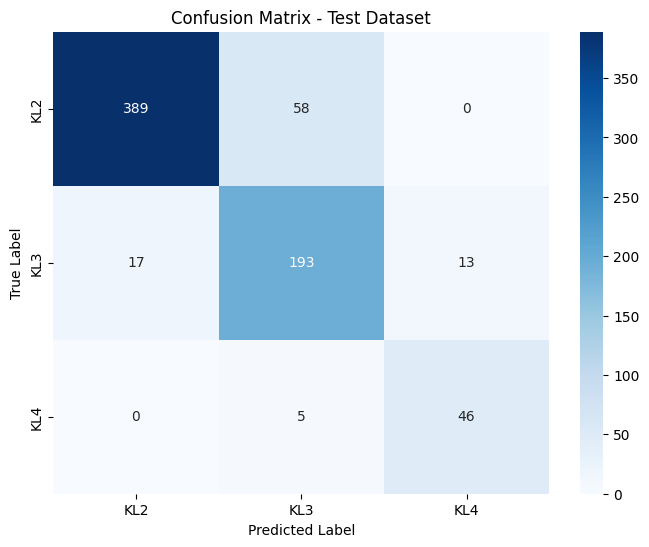

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [25]:
from sklearn.metrics import cohen_kappa_score
import torch

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on the test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Calculate Quadratic Weighted Kappa (QWK)
qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")

Quadratic Weighted Kappa (QWK): 0.8402


## Final evaluation with TTA (original + horizontal flip) and QWK

In [26]:
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix

@torch.no_grad()
def predict_probs(loader, tta=True):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device, memory_format=torch.channels_last)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)

probs, labels = predict_probs(test_loader, tta=True)
pred_argmax = probs.argmax(1)
pred_expect = (probs * torch.arange(NUM_CLASSES)).sum(1).round().long().clamp(0, NUM_CLASSES - 1)   # ordinal-aware rounding

for name, pr in [("argmax", pred_argmax), ("expected-grade rounding", pred_expect)]:
    acc = (pr == labels).float().mean().item() * 100
    qwk = cohen_kappa_score(labels, pr, weights='quadratic')
    print(f"{name:25s} | acc {acc:.2f}% | QWK {qwk:.4f}")

print(classification_report(labels, pred_argmax, target_names=CLASS_NAMES, zero_division=0))
print(confusion_matrix(labels, pred_argmax))


argmax                    | acc 87.52% | QWK 0.8445
expected-grade rounding   | acc 56.03% | QWK 0.4703
              precision    recall  f1-score   support

         KL2       0.95      0.89      0.92       447
         KL3       0.77      0.85      0.81       223
         KL4       0.78      0.88      0.83        51

    accuracy                           0.88       721
   macro avg       0.83      0.87      0.85       721
weighted avg       0.88      0.88      0.88       721

[[396  51   0]
 [ 20 190  13]
 [  0   6  45]]
